In [1]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [3]:
file_path = '/Users/xavierxiong/Desktop/银行B端项目资料/常农项目材料-20240804/第三周/代码和数据/2关联规则/bank_prod_order(1).csv'
data = pd.read_csv(file_path, encoding='gbk')
data.head()

,OrderNumber,CSR_ID,PROD
0,0,30924038,抵押贷
1,1,30924038,黄金1号
2,2,30924038,网银
3,2,30924038,想分就分
4,4,30924062,pos贷


In [22]:
grouped = data.groupby('CSR_ID')['PROD'].apply(list)

In [23]:
grouped

CSR_ID
335380                        [加速积分]
337320                         [好享贷]
339311      [财务通, 好享贷, 基金, 手机银行, 网银]
351538                         [好享贷]
367537                     [好享贷, 网银]
                      ...           
39106312                      [用卡无忧]
39119495                  [pos贷, 网银]
39120376                      [pos贷]
39123188                      [pos贷]
39226449                       [理财宝]
Name: PROD, Length: 720, dtype: object

In [24]:
te = TransactionEncoder()
te_ary = te.fit(grouped).transform(grouped)
df = pd.DataFrame(te_ary, columns=te.columns_)
df

,pos贷,乐享无忧,加速积分,基金,外汇保,好享贷,定存,想分就分,房贷,手机银行,...,教育储蓄,现金宝,理财宝,理财顾问,用卡无忧,第三方存管,网银,财务通,随时存,黄金1号
0,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,True,False,False,False,True,...,False,False,False,False,False,False,True,True,False,False
3,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
716,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
717,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
718,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [25]:
#函数
def encode_units(x):
    if x ==True:
        return 1
    else:
        return 0

In [26]:
df=df.applymap(encode_units)
df.head()

,pos贷,乐享无忧,加速积分,基金,外汇保,好享贷,定存,想分就分,房贷,手机银行,...,教育储蓄,现金宝,理财宝,理财顾问,用卡无忧,第三方存管,网银,财务通,随时存,黄金1号
0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,1,0,0,0,1,...,0,0,0,0,0,0,1,1,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [27]:
frequent_itemsets = apriori(df, min_support=0.01, use_colnames=True)
frequent_itemsets

/Users/xavierxiong/opt/anaconda3/lib/python3.9/site-packages/mlxtend/frequent_patterns/fpcommon.py:111: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
0,0.141667,(pos贷)
1,0.077778,(加速积分)
2,0.065278,(基金)
3,0.130556,(外汇保)
4,0.623611,(好享贷)
...,...,...
230,0.013889,"(黄金1号, 网银, 定存, 好享贷, 外汇保)"
231,0.019444,"(想分就分, 黄金1号, 网银, 好享贷, 外汇保)"
232,0.013889,"(黄金1号, 网银, 好享贷, 手机银行, 外汇保)"
233,0.011111,"(想分就分, 黄金1号, 网银, 手机银行, 外汇保)"


In [28]:
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
0,(外汇保),(pos贷),0.130556,0.141667,0.022222,0.170213,1.201502,0.003727,1.034402
1,(pos贷),(外汇保),0.141667,0.130556,0.022222,0.156863,1.201502,0.003727,1.031202
2,(定存),(pos贷),0.090278,0.141667,0.013889,0.153846,1.085973,0.001100,1.014394
3,(pos贷),(定存),0.141667,0.090278,0.013889,0.098039,1.085973,0.001100,1.008605
4,(pos贷),(想分就分),0.141667,0.076389,0.022222,0.156863,2.053476,0.011400,1.095446
...,...,...,...,...,...,...,...,...,...
1397,(想分就分),"(财务通, 外汇保, 网银, 黄金1号)",0.076389,0.022222,0.013889,0.181818,8.181818,0.012191,1.195062
1398,(黄金1号),"(财务通, 外汇保, 想分就分, 网银)",0.115278,0.016667,0.013889,0.120482,7.228916,0.011968,1.118037
1399,(网银),"(财务通, 外汇保, 想分就分, 黄金1号)",0.709722,0.016667,0.013889,0.019569,1.174168,0.002060,1.002961
1400,(财务通),"(外汇保, 网银, 想分就分, 黄金1号)",0.122222,0.038889,0.013889,0.113636,2.922078,0.009136,1.084330


In [29]:
#可以根据需要进行后续处理，如按照confidence和lift过滤后，按support排序
conf = rules[(rules.confidence > 0.1) & (rules.lift > 1)]
conf.sort_values(by='support', ascending=False).head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
85,(网银),(手机银行),0.709722,0.244444,0.2000,0.281800,1.152820,0.026512,1.052013
84,(手机银行),(网银),0.244444,0.709722,0.2000,0.818182,1.152820,0.026512,1.596528
433,(网银),"(手机银行, 好享贷)",0.709722,0.145833,0.1125,0.158513,1.086944,0.008999,1.015068
432,(手机银行),"(好享贷, 网银)",0.244444,0.422222,0.1125,0.460227,1.090012,0.009290,1.070409
431,"(好享贷, 网银)",(手机银行),0.422222,0.244444,0.1125,0.266447,1.090012,0.009290,1.029995


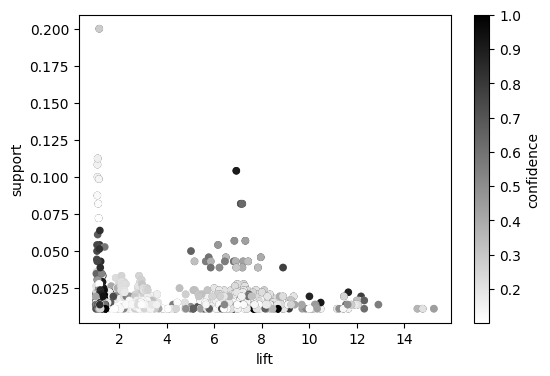

In [30]:
#如果有必要，也可以通过图形看一下规则在支持度，置信度和提升度上的分布情况
import matplotlib.pyplot as plt
%matplotlib inline

ax = plt.subplot()
ax.set_xlabel('lift')
conf.plot.scatter(x="lift", y="support",c="confidence",cmap='binary',
                  figsize=(6,4), ax=ax)

plt.show()

### 练习题1:开通“财务通”的客户应该推荐什么产品？

### 练习题2:开通什么产品的客户应该推荐“好享贷”？